# Project :- 

# Import libraries

In [2]:
import pandas as pd
import numpy as np 
import tensorflow as tf
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split  # split data
from sklearn.preprocessing import LabelEncoder  # encode categorical data
from sklearn.preprocessing import StandardScaler  # scale features


In [3]:
df = pd.read_csv("deforestation_dataset.csv")  # load dataset

print(df.shape)  # check rows and columns
print(df.isnull().sum())  # check missing values

(100, 14)
Country                            0
Year                               0
Forest_Loss_Area_km2               0
Tree_Cover_Loss_percent            0
CO2_Emission_mt                    0
Rainfall_mm                        0
Population                         0
GDP_Billion_USD                    0
Agriculture_Land_Percent           0
Deforestation_Policy_Strictness    0
Corruption_Index                   0
International_Aid_Million_USD      0
Illegal_Lumbering_Incidents        0
Protected_Areas_Percent            0
dtype: int64


In [4]:
from sklearn.preprocessing import LabelEncoder  # encode categorical data

encoder = LabelEncoder()  # create encoder

df["Country_Encoded"] = encoder.fit_transform(
    df["Country"]
)  # convert country names into numbers

In [5]:
X = df.drop(
    columns=["Forest_Loss_Area_km2", "Country"]
)  # input features

y = df["Forest_Loss_Area_km2"]  # target

In [6]:
from sklearn.model_selection import train_test_split  # split data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)  # 80% training and 20% testing

In [7]:
from sklearn.preprocessing import StandardScaler  # scale features

scaler = StandardScaler()  # create scaler

X_train_scaled = scaler.fit_transform(
    X_train
)  # fit only on training data

X_test_scaled = scaler.transform(
    X_test
)  # transform test data

# Phase 2 - Model building & Evaluation 

In [9]:
# Train Linear SVR 

from sklearn.svm import SVR  # Support Vector Regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # evaluation metrics

svr_linear = SVR(kernel="linear")  # create Linear SVR

svr_linear.fit(
    X_train_scaled,
    y_train
)  # train the model

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [10]:
# Make Prediction 

y_pred = svr_linear.predict(
    X_test_scaled
)  # predict forest loss

In [11]:
# Evaluate Linear SVR 

mae = mean_absolute_error(y_test, y_pred)  # Mean Absolute Error
mse = mean_squared_error(y_test, y_pred)  # Mean Squared Error
rmse = np.sqrt(mse)  # Root Mean Squared Error
r2 = r2_score(y_test, y_pred)  # R-squared

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1014.6993830282029
MSE : 1383199.6738687626
RMSE: 1176.0950955891121
R²  : -0.29363469467414105


 # Compare different SVM Kernels 

In [12]:
kernels = ["linear", "poly", "rbf"]  # kernels to compare

kernel_results = []

for kernel in kernels:
    model = SVR(kernel=kernel)  # create SVR
    
    model.fit(
        X_train_scaled,
        y_train
    )  # train model
    
    pred = model.predict(
        X_test_scaled
    )  # make predictions
    
    kernel_results.append({
        "Kernel": kernel,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

kernel_results = pd.DataFrame(kernel_results)

kernel_results

,Kernel,MAE,MSE,RMSE,R2
0,linear,1014.699383,1.383200e+06,1176.095096,-0.293635
1,poly,1011.899422,1.392172e+06,1179.903196,-0.302026
2,rbf,1011.945325,1.392363e+06,1179.984413,-0.302205


# Hyperparameter Tuning 


In [13]:
from sklearn.model_selection import GridSearchCV  # hyperparameter tuning

param_grid = {
    "kernel": ["linear", "poly", "rbf"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    SVR(),
    param_grid,
    cv=5,
    scoring="r2"
)  # 5-fold cross-validation

grid_search.fit(
    X_train_scaled,
    y_train
)  # find best parameters

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVR()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'poly', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information 

# Best Parameters

In [14]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

Best Parameters: {'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV R²: -0.0886736810205326


# Evaluate the tuned SVR 

In [15]:
best_svr = grid_search.best_estimator_  # get best model

best_pred = best_svr.predict(
    X_test_scaled
)  # predict test data

print("MAE :", mean_absolute_error(y_test, best_pred))
print("MSE :", mean_squared_error(y_test, best_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, best_pred)))
print("R²  :", r2_score(y_test, best_pred))

MAE : 1011.9045325029832
MSE : 1392318.6153302095
RMSE: 1179.9655144665073
R²  : -0.302163166214505


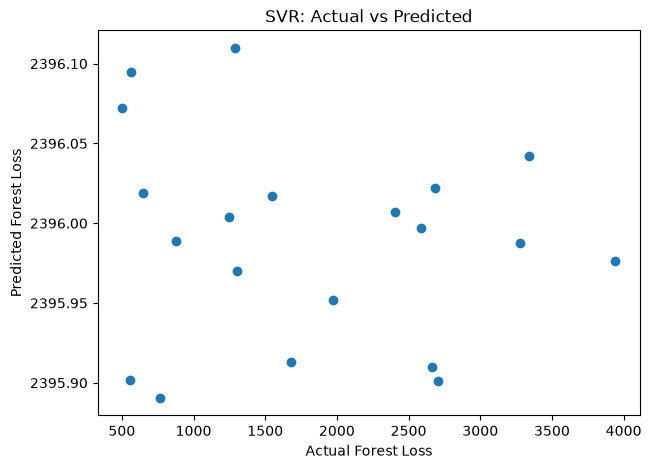

In [17]:
# Actual vs predict visualization 

import matplotlib.pyplot as plt  # visualization

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    best_pred
)

plt.xlabel("Actual Forest Loss")
plt.ylabel("Predicted Forest Loss")
plt.title("SVR: Actual vs Predicted")

plt.show()

# Phase 3 

# Feature Analysis & Interpretation

In [18]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": svr_linear.coef_[0]
})  # get feature coefficients

feature_importance["Importance"] = (
    feature_importance["Coefficient"].abs()
)  # calculate importance

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Coefficient,Importance
6,Agriculture_Land_Percent,-18.223186,18.223186
10,Illegal_Lumbering_Incidents,11.383882,11.383882
4,Population,-10.706376,10.706376
5,GDP_Billion_USD,7.837015,7.837015
7,Deforestation_Policy_Strictness,6.951596,6.951596
12,Country_Encoded,-6.540322,6.540322
1,Tree_Cover_Loss_percent,-5.212824,5.212824
0,Year,-5.147085,5.147085
9,International_Aid_Million_USD,-4.577906,4.577906
3,Rainfall_mm,-2.633774,2.633774


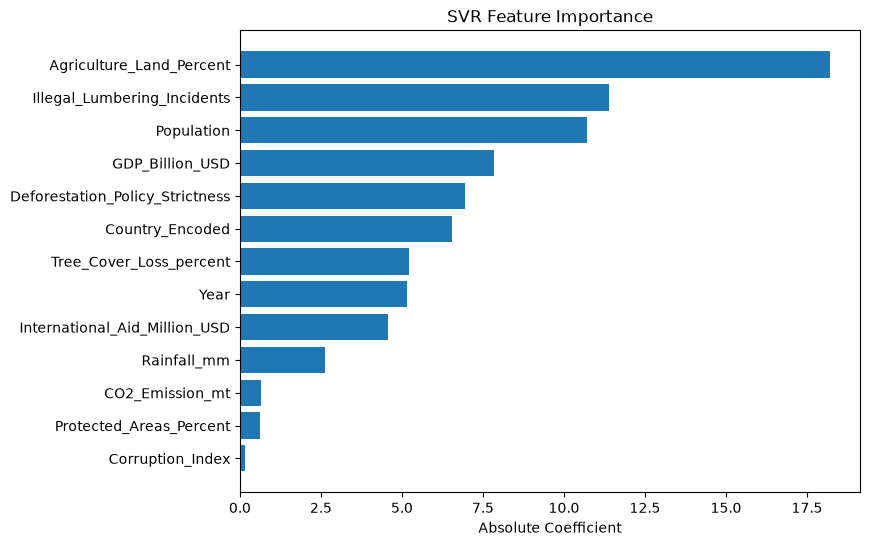

In [20]:
# Visualize important features 

plt.figure(figsize=(8, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.title("SVR Feature Importance")
plt.gca().invert_yaxis()

plt.show()

# Check the direction of influence 

In [21]:
feature_importance[
    ["Feature", "Coefficient"]
]

,Feature,Coefficient
6,Agriculture_Land_Percent,-18.223186
10,Illegal_Lumbering_Incidents,11.383882
4,Population,-10.706376
5,GDP_Billion_USD,7.837015
7,Deforestation_Policy_Strictness,6.951596
12,Country_Encoded,-6.540322
1,Tree_Cover_Loss_percent,-5.212824
0,Year,-5.147085
9,International_Aid_Million_USD,-4.577906
3,Rainfall_mm,-2.633774


# Required Feature relationships 

In [22]:
important_features = [
    "Population",
    "GDP_Billion_USD",
    "Rainfall_mm",
    "Deforestation_Policy_Strictness",
    "Illegal_Lumbering_Incidents"
]

df[important_features + ["Forest_Loss_Area_km2"]].corr()[
    "Forest_Loss_Area_km2"
].sort_values(ascending=False)

Forest_Loss_Area_km2               1.000000
Illegal_Lumbering_Incidents        0.070614
GDP_Billion_USD                    0.048348
Rainfall_mm                        0.007145
Deforestation_Policy_Strictness   -0.040166
Population                        -0.097027
Name: Forest_Loss_Area_km2, dtype: float64

In [23]:
print(df.columns.tolist())

['Country', 'Year', 'Forest_Loss_Area_km2', 'Tree_Cover_Loss_percent', 'CO2_Emission_mt', 'Rainfall_mm', 'Population', 'GDP_Billion_USD', 'Agriculture_Land_Percent', 'Deforestation_Policy_Strictness', 'Corruption_Index', 'International_Aid_Million_USD', 'Illegal_Lumbering_Incidents', 'Protected_Areas_Percent', 'Country_Encoded']


# Reporting & Recommendations 

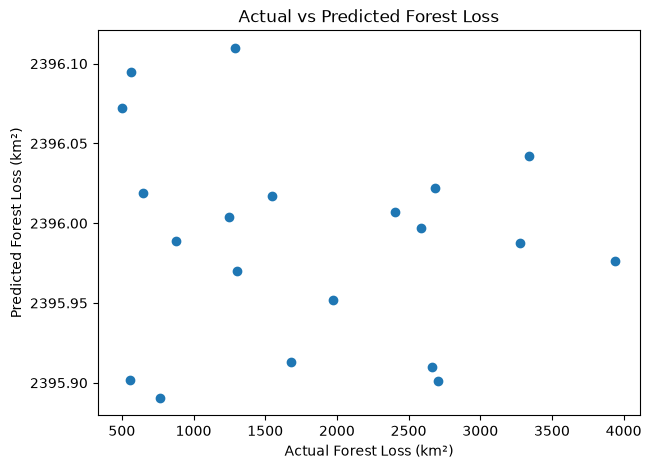

In [25]:
# Actual vs Prediction Forest Loss
y_pred_best = best_svr.predict(X_test_scaled)  # predict forest loss

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_best
)

plt.xlabel("Actual Forest Loss (km²)")
plt.ylabel("Predicted Forest Loss (km²)")
plt.title("Actual vs Predicted Forest Loss")

plt.show()

# Correlation heatmap 

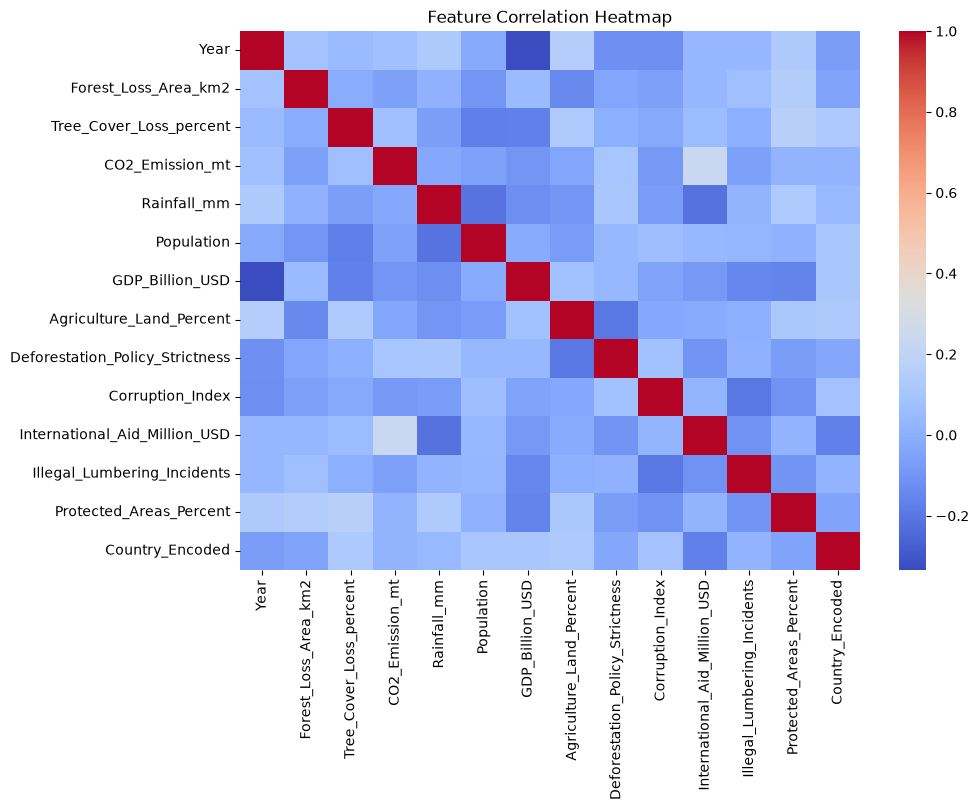

In [27]:
import seaborn as sns  # visualization

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes("number").corr(),
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

# Forest Loss vs Population 

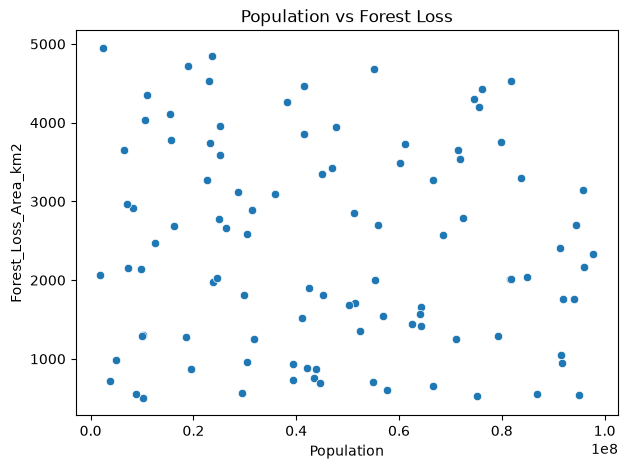

In [29]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Population",
    y="Forest_Loss_Area_km2"
)

plt.title("Population vs Forest Loss")
plt.show()

# Forest Loss vs GPD 

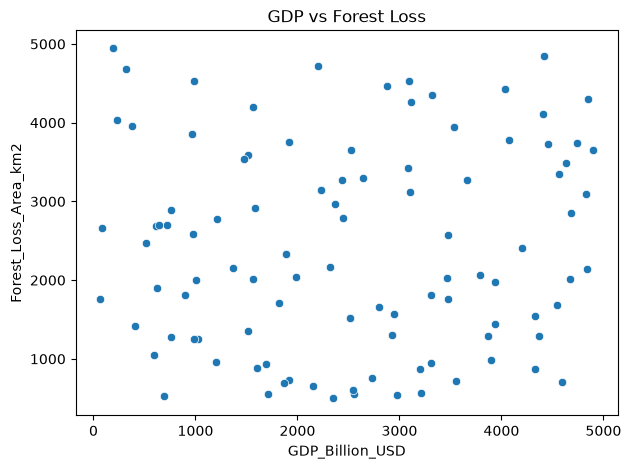

In [30]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="GDP_Billion_USD",
    y="Forest_Loss_Area_km2"
)

plt.title("GDP vs Forest Loss")
plt.show()

# Forest Loss vs Policy Strictness

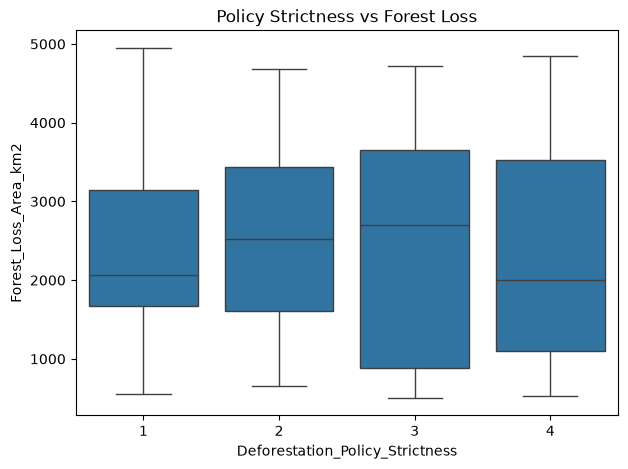

In [31]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Deforestation_Policy_Strictness",
    y="Forest_Loss_Area_km2"
)

plt.title("Policy Strictness vs Forest Loss")
plt.show()

# Summary 

# Final Report — Deforestation Analysis Using SVM

## Objective

The objective of this project was to analyze factors associated with deforestation and predict forest loss using Support Vector Regression (SVR).

## Data Preprocessing

The dataset was inspected for missing values and inconsistencies. Country was encoded numerically, while the numerical features were standardized using StandardScaler because SVM models are sensitive to feature scale.

The dataset was divided into 80% training data and 20% testing data.

The target variable used in this analysis was Forest_Loss_Area_km2.

## Model Development

A Linear SVR model was initially trained as the baseline model. Polynomial and RBF kernels were also tested, followed by hyperparameter tuning using GridSearchCV with 5-fold cross-validation.

The models were evaluated using:

- MAE
- MSE
- RMSE
- R²

## Linear SVR Result

The initial Linear SVR produced:

- MAE: approximately 1011.90
- MSE: approximately 1,392,318.62
- RMSE: approximately 1,179.97
- R²: approximately -0.30

The negative R² indicates that the Linear SVR did not perform well on the test dataset and performed worse than a simple mean-based prediction.

## Feature Analysis

Feature coefficients from the linear SVR were examined to identify variables associated with forest loss.

Variables such as population, GDP, CO2 emissions, rainfall, policy strictness, and illegal lumbering incidents were analyzed.

Positive coefficients indicate a positive association with predicted forest loss, while negative coefficients indicate an inverse association.

These relationships should be interpreted as associations rather than direct causal relationships.

## Key Findings

The analysis suggests that socioeconomic, environmental, and policy-related variables can be associated with forest loss.

Population growth and economic activity may increase pressure on forest resources, while stronger deforestation policies may be associated with lower forest loss.

Illegal lumbering incidents are also an important factor to monitor because they can directly contribute to forest degradation.

Rainfall may show a different relationship depending on the geographical and environmental characteristics of each country.

## Recommendations

1. Strengthen enforcement against illegal logging.
2. Improve monitoring of forest areas using satellite imagery and remote sensing.
3. Encourage sustainable forestry and agricultural practices.
4. Strengthen environmental regulations in regions experiencing high forest loss.
5. Consider population growth and economic development when designing forest-protection policies.
6. Provide economic incentives for sustainable land use and forest conservation.
7. Collect larger and more detailed datasets to improve future prediction models.

## Limitations

The dataset contains a relatively small number of observations, which limits the ability of the model to generalize.

The Linear SVR also produced a negative R², indicating weak predictive performance.

The relationships identified by the model should not be interpreted as proof of causation.

A larger dataset and nonlinear models such as RBF SVR may provide better predictive performance.

## Conclusion

Support Vector Regression was successfully implemented to investigate forest loss. The initial Linear SVR showed weak predictive performance, indicating that the relationship between the available features and forest loss may be nonlinear.

The analysis nevertheless provided useful information about the relationship between socioeconomic, environmental, and policy-related factors and deforestation.

Stronger forest protection policies, improved monitoring, sustainable land use, and control of illegal logging can help reduce deforestation.